# LifeSnaps: night physiology, latent recovery, and mood
**Project:** EEE6778 Applied Machine Learning II, Deliverable 2 · **Author:** Maitrey Phatak (m.phatak@ufl.edu)

**Question.** Does nightly physiological recovery, measured by a Fitbit, explain how people report feeling the next day?

**What this notebook does.**
1. Converts the raw LifeSnaps Fitbit export (9.1 GB BSON) to Parquet once and queries it with DuckDB.
2. Cleans the sleep records and links mood reports to nights.
3. Computes ten night features from 5 s heart rate, 5 min HRV, sleep stages and wrist temperature.
4. Fits four model families: logistic baselines, a Kalman state space model of recovery (1 to 3 hidden states, mood inside),
   a hidden Markov model with mood as categories, and a mixed model with per person coupling.
5. Exports the model outputs for the Streamlit recovery tracker (`ui/app.py`).

**This copy was executed on UF HiPerGator** (Open OnDemand Jupyter, 16 GB, 4 cores) on 18 Nov 2026; all outputs below are from the real data.
To rerun, download `rais_anonymized.zip` from Zenodo record 7229547, unzip it under `~/Data Analysis Zenodo/Data/`
(or set `LS_BASE`), and run all cells (about 10 minutes; the first run adds about 3 minutes for the Parquet conversion).

**Headline results.** Short nights raise the overnight heart rate floor (+0.49 SD) and lower HRV (−0.33 SD). BIC selects three hidden states:
autonomic strain (half life about 0.6 days), within night trajectory, and sleep fragmentation. None of them improves held out mood prediction
(best balanced accuracy 0.357, chance 0.143), and no person shows a mood to recovery slope above 0.2.

In [2]:
%pip install -q pymongo pyarrow duckdb pandas numpy scipy matplotlib scikit-learn statsmodels

## 0. Setup
Installs and imports the libraries, defines the data paths, and a streaming reader for BSON files (the raw files are too large to load whole).

In [1]:
import os, collections
from pathlib import Path
from time import time
import numpy as np, pandas as pd, duckdb, bson
import pyarrow as pa, pyarrow.parquet as pq
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import logsumexp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score
import statsmodels.formula.api as smf
import warnings; warnings.filterwarnings("ignore")

BASE = Path(os.environ.get("LS_BASE", Path.home() / "Data Analysis Zenodo"))
RAW = BASE / "Data/rais_anonymized/mongo_rais_anonymized"
CSV = BASE / "Data/rais_anonymized/csv_rais_anonymized"
OUT = BASE / "parquet"; OUT.mkdir(exist_ok=True); P = str(OUT)
FIG = BASE / "figures"; FIG.mkdir(exist_ok=True)
con = duckdb.connect()

def records(path):
    with open(path, "rb") as fh:
        yield from bson.decode_file_iter(fh)

print("raw files:", sorted(p.name for p in RAW.iterdir()))

raw files: ['fitbit.bson', 'fitbit.metadata.json', 'sema.bson', 'sema.metadata.json', 'surveys.bson', 'surveys.metadata.json']


### Decisions
Every analysis choice lives in this cell. Change a value and rerun the notebook to see its effect.
Defaults: both heart rate filters off (they affect under 0.5% of readings), valid nights 180 to 900 minutes asleep (rule from the public
LifeSnaps multilevel analysis), at least 14 mood reports per person, last 30% of each person's data held out, z scores capped at ±4.
The valence and arousal map places the 7 mood categories on the circumplex of affect; it is used only in section 8 and is an approximation.

In [2]:
HR_DROP_CONF0 = False        # drop heart rate readings with confidence 0
HR_DEDUP = False             # drop duplicate heart rate rows
MIN_ASLEEP, MAX_ASLEEP = 180, 900   # valid night, minutes asleep
MIN_REPORTS = 14             # minimum mood reports per person
TEST_FRAC = 0.3              # last share of each person's data used for testing
Z_CLIP = 4                   # cap on per person z scores
PREV_MOOD_MAX = "36h"        # previous mood counts only if this recent
VALID = ["RESTED/RELAXED", "TIRED", "NEUTRAL", "HAPPY", "TENSE/ANXIOUS", "ALERT", "SAD"]
VA = {"HAPPY": (1, .5), "RESTED/RELAXED": (.5, -1), "ALERT": (.5, 1), "NEUTRAL": (0, 0),
      "TIRED": (-.5, -1), "TENSE/ANXIOUS": (-1, 1), "SAD": (-1, -.5)}   # valence, arousal (section 8 only)

## 1. Raw export to Parquet
Streams `fitbit.bson` once and writes five Parquet files: heart rate (id, ts, bpm, confidence), HRV every 5 min (rmssd, coverage, LF, HF),
wrist temperature, one row per sleep log, and one row per sleep stage bout. Skipped when the files already exist.

In [3]:
need = [OUT / f for f in ["hr.parquet", "hrv5.parquet", "wrist_temp.parquet", "sleep_nights.parquet", "sleep_stages.parquet"]]
if all(p.exists() for p in need):
    print("Parquet files present, skipping conversion")
else:
    NAMES = {"heart_rate": "hr", "Heart Rate Variability Details": "hrv5", "Wrist Temperature": "wrist_temp"}
    def to_row(t, i, x):
        if t == "heart_rate":
            return {"id": i, "ts": x["dateTime"], "bpm": x["value"]["bpm"], "conf": x["value"].get("confidence")}
        if t == "Heart Rate Variability Details":
            return {"id": i, "ts": x["timestamp"], "rmssd": x["rmssd"], "coverage": x["coverage"],
                    "lf": x["low_frequency"], "hf": x["high_frequency"]}
        return {"id": i, "ts": x["recorded_time"], "temp": x["temperature"]}
    buf, writers, nights_rows, stage_rows = collections.defaultdict(list), {}, [], []
    def flush(name):
        df = pd.DataFrame(buf[name]); df["ts"] = pd.to_datetime(df["ts"], format="ISO8601")
        tbl = pa.Table.from_pandas(df, preserve_index=False)
        if name not in writers: writers[name] = pq.ParquetWriter(OUT / f"{name}.parquet", tbl.schema)
        writers[name].write_table(tbl); buf[name].clear()
    t0 = time()
    for k, d in enumerate(records(RAW / "fitbit.bson")):
        t = d.get("type")
        if t in NAMES:
            buf[NAMES[t]].append(to_row(t, str(d["id"]), d["data"]))
            if len(buf[NAMES[t]]) >= 500_000: flush(NAMES[t])
        elif t == "sleep":
            x = d["data"]; i = str(d["id"])
            nights_rows.append({"id": i, "logId": x["logId"], "dateOfSleep": x["dateOfSleep"], "start": x["startTime"],
                                "end": x["endTime"], "mainSleep": x["mainSleep"], "minutesAsleep": x["minutesAsleep"],
                                "efficiency": x["efficiency"], "kind": x["type"]})
            for part in ["data", "shortData"]:
                for s in x.get("levels", {}).get(part, []):
                    stage_rows.append({"id": i, "logId": x["logId"], "part": part, "ts": s["dateTime"],
                                       "level": s["level"], "seconds": s["seconds"]})
        if k % 10_000_000 == 0: print(f"{k:,} records, {time()-t0:.0f}s")
    for name in list(buf):
        if buf[name]: flush(name)
    for w in writers.values(): w.close()
    pd.DataFrame(nights_rows).to_parquet(OUT / "sleep_nights.parquet")
    st_ = pd.DataFrame(stage_rows); st_["ts"] = pd.to_datetime(st_["ts"], format="ISO8601"); st_.to_parquet(OUT / "sleep_stages.parquet")
    print("done in", round(time() - t0), "s")

Parquet files present, skipping conversion


## 2. Mood reports
Reads `sema.bson`, keeps the Context and Mood Survey, and keeps the 7 valid mood categories (8 answers outside the option list are dropped).
Each report is linked to the night that ended before it: a report before 06:00 belongs to the previous night.
`prev` is the person's previous mood if it was reported within 36 hours. `win` is each person's mood reporting window (first to last prompt).

In [4]:
sema = pd.DataFrame([{"id": str(d["user_id"]), **{k: (d.get("data") or {}).get(k)
                       for k in ["SURVEY_NAME", "SCHEDULED_TS", "COMPLETED_TS", "MOOD"]}}
                     for d in records(RAW / "sema.bson")])
print(sema.SURVEY_NAME.value_counts().to_string(), "\n"); print(sema.MOOD.value_counts(dropna=False).to_string())

cm = sema[sema.SURVEY_NAME == "Context and Mood Survey"].copy()
cm["sched"] = pd.to_datetime(cm.SCHEDULED_TS, format="ISO8601", errors="coerce")
win = cm.dropna(subset=["sched"]).groupby("id").sched.agg(first="min", last="max").reset_index()

reps = cm[cm.MOOD.isin(VALID)].copy()
reps["t"] = pd.to_datetime(reps.COMPLETED_TS, format="ISO8601", errors="coerce")
reps = reps.dropna(subset=["t"]).sort_values(["id", "t"]).reset_index(drop=True)
reps["date"] = (reps.t - pd.Timedelta(hours=6)).dt.normalize()        # report before 6 am belongs to the previous night
reps["slot"] = pd.cut(reps.t.dt.hour, [-1, 5, 12, 17, 24], labels=["night", "morning", "afternoon", "evening"])
grp = reps.groupby("id")
reps["prev"] = grp.MOOD.shift(1).where(reps.t - grp.t.shift(1) <= pd.Timedelta(PREV_MOOD_MAX)).fillna("none")
print(f"\nvalid reports: {len(reps)}, people: {reps.id.nunique()}, dropped labels outside the 7 moods: "
      f"{(cm.MOOD.notna() & ~cm.MOOD.isin(VALID + ['<no-response>'])).sum()}")

SURVEY_NAME
Context and Mood Survey    11526
Step Goal Survey            3852 

MOOD
<no-response>     10343
RESTED/RELAXED     1179
TIRED              1126
NEUTRAL             822
HAPPY               789
TENSE/ANXIOUS       620
ALERT               345
SAD                 147
SURPRISE              2
ANGER                 2
SADNESS               2
None                  1
FEAR                  1
JOY                   1

valid reports: 5028, people: 63, dropped labels outside the 7 moods: 8


## 3. Cleaning
**Funnel:** main sleep only → 180 to 900 minutes asleep → one night per date (longest kept) → inside the person's mood window.
The second cell reports raw heart rate quality (duplicate rows, confidence 0 readings) and builds the heart rate source used below.

In [5]:
nights = con.sql(f"SELECT * FROM '{P}/sleep_nights.parquet'").df()
nights["date"] = pd.to_datetime(nights.dateOfSleep)
steps_log = [("all sleep records", nights)]
x_ = nights[nights.mainSleep];                                         steps_log.append(("main sleep only", x_))
x_ = x_[x_.minutesAsleep.between(MIN_ASLEEP, MAX_ASLEEP)];             steps_log.append((f"{MIN_ASLEEP} to {MAX_ASLEEP} min asleep", x_))
x_ = x_.sort_values("minutesAsleep").drop_duplicates(["id", "date"], keep="last"); steps_log.append(("one night per date", x_))
x_ = x_.merge(win, on="id")
x_ = x_[(x_.date >= x_["first"].dt.normalize()) & (x_.date <= x_["last"].dt.normalize() + pd.Timedelta("1D"))]
steps_log.append(("inside mood window", x_))
clean = x_.drop(columns=["first", "last"]).reset_index(drop=True)
funnel = pd.DataFrame([(k, len(v), v.id.nunique()) for k, v in steps_log], columns=["step", "nights", "people"])
funnel

,step,nights,people
0,all sleep records,4141,69
1,main sleep only,3688,69
2,180 to 900 min asleep,3562,65
3,one night per date,3431,65
4,inside mood window,2338,57


In [6]:
print(con.sql(f"SELECT count(*) - count(DISTINCT (id, ts)) AS duplicate_hr_rows FROM '{P}/hr.parquet'").df().to_string(index=False))
print(con.sql(f"SELECT conf, count(*) AS n FROM '{P}/hr.parquet' GROUP BY conf ORDER BY conf").df().to_string(index=False))
HR_SRC = (f"(SELECT {'DISTINCT ' if HR_DEDUP else ''}id, ts, bpm FROM '{P}/hr.parquet'"
          f"{' WHERE conf > 0' if HR_DROP_CONF0 else ''})")
print("heart rate source:", HR_SRC)

 duplicate_hr_rows
            134133
 conf        n
    0    98586
    1 25632169
    2  8883731
    3 14105554
heart rate source: (SELECT id, ts, bpm FROM '/home/m.phatak/Data Analysis Zenodo/parquet/hr.parquet')


## 4. Night features
For every cleaned night, computed in SQL over the Parquet files:
- **Heart rate** (5 min medians): nadir, nadir timing as a fraction of the night, drop from the first 10% to 20 to 30% of the night, mean.
- **HRV:** mean RMSSD, and late third minus early third.
- **Stages:** deep fraction of sleep, share of deep sleep in the first half, wake bouts per hour (rates, because counts scale with night length).
- **Wrist temperature:** mean during sleep.

Features are then z scored within each person, so every value means "compared with this person's usual night".

In [7]:
nn = clean[["id", "logId", "date", "minutesAsleep"]].copy()
nn["s"] = pd.to_datetime(clean.start, format="ISO8601"); nn["e"] = pd.to_datetime(clean.end, format="ISO8601")
con.register("nn", nn)
t0 = time()
feat = con.sql(f'''
WITH hr5 AS (
  SELECT nn.logId, time_bucket(INTERVAL 5 MINUTE, h.ts) b, median(h.bpm) bpm,
         epoch(time_bucket(INTERVAL 5 MINUTE, h.ts) - nn.s) / epoch(nn.e - nn.s) frac
  FROM nn JOIN {HR_SRC} h ON h.id = nn.id AND h.ts BETWEEN nn.s AND nn.e GROUP BY ALL),
hrf AS (SELECT logId, min(bpm) hr_nadir, arg_min(frac, bpm) nadir_frac, avg(bpm) hr_mean,
          avg(bpm) FILTER (frac < 0.1) - avg(bpm) FILTER (frac BETWEEN 0.2 AND 0.3) hr_drop
        FROM hr5 GROUP BY logId),
hv AS (SELECT nn.logId, avg(v.rmssd) rmssd_mean,
          avg(v.rmssd) FILTER (epoch(v.ts - nn.s) / epoch(nn.e - nn.s) > 0.66)
        - avg(v.rmssd) FILTER (epoch(v.ts - nn.s) / epoch(nn.e - nn.s) < 0.33) rmssd_late_minus_early
       FROM nn JOIN '{P}/hrv5.parquet' v ON v.id = nn.id AND v.ts BETWEEN nn.s AND nn.e GROUP BY nn.logId),
st AS (SELECT st.logId,
          sum(st.seconds) FILTER (st.level = 'deep' AND st.part = 'data') / 60 deep_min,
          sum(st.seconds) FILTER (st.level = 'deep' AND st.part = 'data' AND epoch(st.ts - nn.s) / epoch(nn.e - nn.s) < 0.5)
            / nullif(sum(st.seconds) FILTER (st.level = 'deep' AND st.part = 'data'), 0) deep_first_half,
          count(*) FILTER (st.level = 'wake') wake_bouts
       FROM '{P}/sleep_stages.parquet' st JOIN nn ON st.logId = nn.logId GROUP BY st.logId),
tp AS (SELECT nn.logId, avg(t.temp) temp_mean
       FROM nn JOIN '{P}/wrist_temp.parquet' t ON t.id = nn.id AND t.ts BETWEEN nn.s AND nn.e GROUP BY nn.logId)
SELECT nn.id, nn.date, nn.minutesAsleep, hrf.hr_nadir, hrf.nadir_frac, hrf.hr_mean, hrf.hr_drop,
       hv.rmssd_mean, hv.rmssd_late_minus_early, st.deep_min, st.deep_first_half, st.wake_bouts, tp.temp_mean
FROM nn LEFT JOIN hrf ON hrf.logId = nn.logId LEFT JOIN hv ON hv.logId = nn.logId
        LEFT JOIN st ON st.logId = nn.logId LEFT JOIN tp ON tp.logId = nn.logId''').df()
feat["date"] = pd.to_datetime(feat["date"]).astype("datetime64[ns]")
feat["nadir_frac"] = feat.nadir_frac.clip(0, 1)
feat["wake_per_h"] = feat.wake_bouts / (feat.minutesAsleep / 60)
feat["deep_frac"] = feat.deep_min / feat.minutesAsleep
feat.to_parquet(OUT / "night_features_clean.parquet")
print(f"{len(feat)} nights, {feat.id.nunique()} people, {time()-t0:.0f}s")

F = ["minutesAsleep", "hr_nadir", "nadir_frac", "hr_drop", "rmssd_mean", "rmssd_late_minus_early",
     "deep_frac", "deep_first_half", "wake_per_h", "temp_mean"]
AVG = ["minutesAsleep", "hr_mean", "rmssd_mean"]
zz = feat.copy()
for c in sorted(set(F + AVG)):
    zz[c] = zz.groupby("id")[c].transform(lambda s: ((s - s.mean()) / s.std()).clip(-Z_CLIP, Z_CLIP))
feat[F + ["hr_mean"]].describe().T.round(2)

2338 nights, 57 people, 1s


,count,mean,std,min,25%,50%,75%,max
minutesAsleep,2338.0,403.09,85.15,180.00,350.00,405.00,456.00,818.00
hr_nadir,2324.0,55.72,7.95,37.00,50.00,55.00,61.00,94.00
nadir_frac,2324.0,0.60,0.28,0.00,0.41,0.65,0.83,1.00
hr_drop,2320.0,2.44,7.09,-71.33,-0.85,1.96,5.40,43.28
rmssd_mean,1609.0,44.11,22.39,9.28,27.43,37.61,54.86,173.81
rmssd_late_minus_early,1600.0,7.21,13.62,-78.01,-0.24,6.54,13.22,75.15
deep_frac,2268.0,0.21,0.09,0.01,0.15,0.20,0.24,1.02
deep_first_half,2246.0,0.80,0.21,0.04,0.67,0.85,1.00,1.00
wake_per_h,2338.0,4.50,1.90,0.00,3.59,4.30,5.11,23.64
temp_mean,2240.0,-0.03,0.67,-7.59,-0.29,0.01,0.29,3.95


## 5. Short nights versus the same person's other nights
A short night is more than 1 SD below the person's usual sleep. Left: mean feature difference. Right: feature correlations.
**Result:** heart rate nadir is higher and RMSSD lower after short nights; most shape features barely move.

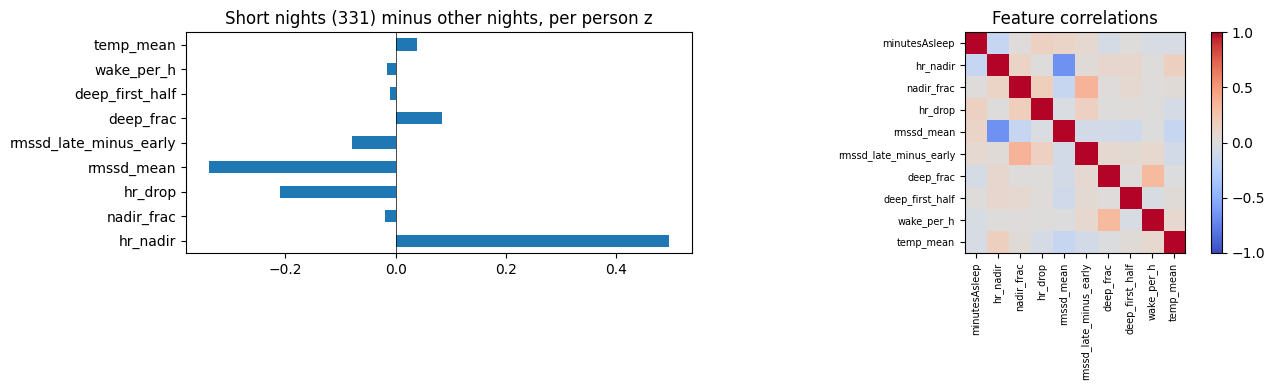

In [8]:
short = zz.minutesAsleep < -1
diff = (zz[short][F].mean() - zz[~short][F].mean()).drop("minutesAsleep")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
diff.plot.barh(ax=ax[0]); ax[0].axvline(0, c="k", lw=.5)
ax[0].set_title(f"Short nights ({short.sum()}) minus other nights, per person z")
im = ax[1].imshow(zz[F].corr(), cmap="coolwarm", vmin=-1, vmax=1)
ax[1].set_xticks(range(len(F)), F, rotation=90, fontsize=7); ax[1].set_yticks(range(len(F)), F, fontsize=7)
ax[1].set_title("Feature correlations"); fig.colorbar(im, ax=ax[1], fraction=.04)
plt.tight_layout(); plt.savefig(FIG / "short_nights.png", dpi=150); plt.show()

## 6. Mood baseline
Does last night help predict the mood a person reports? Multinomial logistic regression (class balanced) on time of day and previous mood,
then adding nightly averages or all night features. Evaluated on each person's last 30% of reports.
**Result:** carry forward 0.357 balanced accuracy; physiology changes the logistic models by −0.011 to −0.004 (chance 0.143).

In [9]:
dlr = reps.merge(zz[["id", "date"] + sorted(set(F + AVG))], on=["id", "date"], how="left")
dlr = dlr[dlr.id.map(dlr.groupby("id").size()) >= MIN_REPORTS].copy()
dlr["rank"] = dlr.groupby("id").t.rank(pct=True)
train_lr, test_lr = dlr[dlr["rank"] <= 1 - TEST_FRAC], dlr[dlr["rank"] > 1 - TEST_FRAC]

def design(df, cols):
    out = pd.get_dummies(df[["slot", "prev"]].astype(str))
    for c in cols: out[c] = df[c].fillna(0); out[c + "_obs"] = df[c].notna().astype(int)
    return out.astype(float)

def fit_eval(train, test, cols):
    Xtr = design(train, cols); Xte = design(test, cols).reindex(columns=Xtr.columns, fill_value=0)
    p = LogisticRegression(max_iter=3000, class_weight="balanced").fit(Xtr, train.MOOD).predict(Xte)
    return balanced_accuracy_score(test.MOOD, p), f1_score(test.MOOD, p, average="macro")

cf = test_lr[test_lr.prev != "none"]
rows = [("carry forward (previous mood)", balanced_accuracy_score(cf.MOOD, cf.prev), f1_score(cf.MOOD, cf.prev, average="macro"))]
for name, cols in [("time + previous mood", []), ("+ nightly averages", AVG), ("+ night features", F)]:
    rows.append((name, *fit_eval(train_lr, test_lr, cols)))
res_lr = pd.DataFrame(rows, columns=["model", "bal_acc", "macro_f1"]).round(3)
print(f"{len(dlr)} reports, {dlr.id.nunique()} people, {len(test_lr)} test reports, "
      f"{dlr[F].notna().any(axis=1).mean():.2f} with night features")
res_lr

4943 reports, 49 people, 1505 test reports, 0.78 with night features


,model,bal_acc,macro_f1
0,carry forward (previous mood),0.357,0.356
1,time + previous mood,0.352,0.304
2,+ nightly averages,0.348,0.314
3,+ night features,0.341,0.304


## 7. Recovery state space model (one hidden state)
$x_t = \phi x_{t-1} + b_{sleep}\,sleep_t + b_{steps}\,steps_{t-1} + w_t$, and each night feature $y_{k,t} = c_k x_t + v_{k,t}$, with $c_{\text{hr\_nadir}} = -1$
fixing scale and sign (higher x = better recovery). The Kalman filter skips missing nights; parameters are fitted by maximum likelihood
(L-BFGS-B) across all 57 people at once. The first cell builds the daily panel, the second fits the model.
**Result:** $\phi$ = 0.37 (half life 0.7 days); the state is mostly HR nadir and RMSSD; more sleep raises it, more steps the day before lower it.

In [10]:
OBS = ["hr_nadir", "rmssd_mean", "hr_drop", "deep_frac", "wake_per_h", "temp_mean",
       "nadir_frac", "rmssd_late_minus_early", "deep_first_half"]
INP = ["minutesAsleep", "steps_prev"]
daily = pd.read_csv(CSV / "daily_fitbit_sema_df_unprocessed.csv", usecols=["id", "date", "steps"], low_memory=False)
daily["id"] = daily.id.astype(str); daily["date"] = pd.to_datetime(daily.date)
daily = daily.drop_duplicates(["id", "date"])
print("ids shared with night features:", len(set(daily.id) & set(feat.id)), "of", feat.id.nunique())

keep_ids = set(feat.id)
pan = pd.concat([pd.DataFrame({"id": w.id, "date": pd.date_range(w.first.normalize(), w.last.normalize() + pd.Timedelta("1D"))})
                 for w in win.itertuples() if w.id in keep_ids], ignore_index=True)
pan = pan.merge(zz[["id", "date"] + OBS + ["minutesAsleep"]], on=["id", "date"], how="left")
sp = daily.assign(date=daily.date + pd.Timedelta("1D")).rename(columns={"steps": "steps_prev"})
pan = pan.merge(sp, on=["id", "date"], how="left")
pan["steps_prev"] = pan.groupby("id").steps_prev.transform(lambda s: ((s - s.mean()) / s.std()).clip(-Z_CLIP, Z_CLIP))
pan = pan.sort_values(["id", "date"]).reset_index(drop=True)
ids = pan.id.unique(); N = len(ids); T = int(pan.groupby("id").size().max()); K1 = len(OBS)
Lens = pan.groupby("id", sort=False).size().reindex(ids).to_numpy()
Y1 = np.full((N, T, K1), np.nan); U = np.zeros((N, T, 2))
for i, (pid, g) in enumerate(pan.groupby("id", sort=False)):
    assert pid == ids[i]
    Y1[i, :len(g)] = g[OBS].to_numpy(); U[i, :len(g)] = g[INP].fillna(0).to_numpy()
print(f"{len(pan)} person days, {N} people, {pan[OBS].notna().any(axis=1).mean():.2f} with a night")

ids shared with night features: 57 of 57
3697 person days, 57 people, 0.63 with a night


In [11]:
def unpack1(th):
    return np.tanh(th[0]), th[1:3], np.r_[-1.0, th[3:2 + K1]], np.exp(th[2 + K1]), 0.05 + np.exp(th[3 + K1:3 + 2 * K1])

def run1(th):
    phi, b, c, q, rn = unpack1(th)
    m, Pv, ll = np.zeros(N), np.ones(N), 0.0
    M, V = np.full((N, T), np.nan), np.full((N, T), np.nan)
    for t in range(T):
        m = phi * m + U[:, t] @ b; Pv = phi ** 2 * Pv + q
        o = ~np.isnan(Y1[:, t]); e = np.where(o, Y1[:, t] - c * m[:, None], 0.0)
        A = (o * c ** 2 / rn).sum(1); Ce = (o * c * e / rn).sum(1); D = 1 + Pv * A
        ll += (-0.5 * ((o * e ** 2 / rn).sum(1) - Pv * Ce ** 2 / D + (o * np.log(rn)).sum(1) + np.log(D)
                       + o.sum(1) * np.log(2 * np.pi))).sum()
        Pv = Pv / D; m = m + Pv * Ce
        M[:, t], V[:, t] = m, Pv
    return ll, M, V

th0 = np.r_[np.arctanh(0.7), 0.1, -0.1, 0.5, np.zeros(K1 - 2), np.log(0.3), np.log(0.8) * np.ones(K1)]
t0 = time(); fit1 = minimize(lambda th: -run1(th)[0], th0, method="L-BFGS-B")
phi1, b1, c1, q1, rn1 = unpack1(fit1.x)
print(fit1.message, f"{time()-t0:.0f}s, loglik {-fit1.fun:.1f}")
print(f"phi={phi1:.3f}  half life={np.log(.5)/np.log(abs(phi1)):.1f} days  b_sleep={b1[0]:.3f}  b_steps_prev={b1[1]:.3f}  q={q1:.3f}")
pd.DataFrame({"loading": c1, "noise": rn1}, index=OBS).round(3)

CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH 5s, loglik -26128.5
phi=0.368  half life=0.7 days  b_sleep=0.163  b_steps_prev=-0.131  q=0.669


,loading,noise
hr_nadir,-1.000,0.142
rmssd_mean,0.793,0.460
hr_drop,-0.008,0.945
deep_frac,-0.096,0.927
wake_per_h,-0.010,0.919
temp_mean,-0.181,0.909
nadir_frac,-0.148,0.958
rmssd_late_minus_early,-0.041,0.941
deep_first_half,-0.101,0.963


The state for the participant with the most nights, and the average response around short nights (95% CI).
**Result:** the state dips on the day of a short night and returns to baseline the next day.

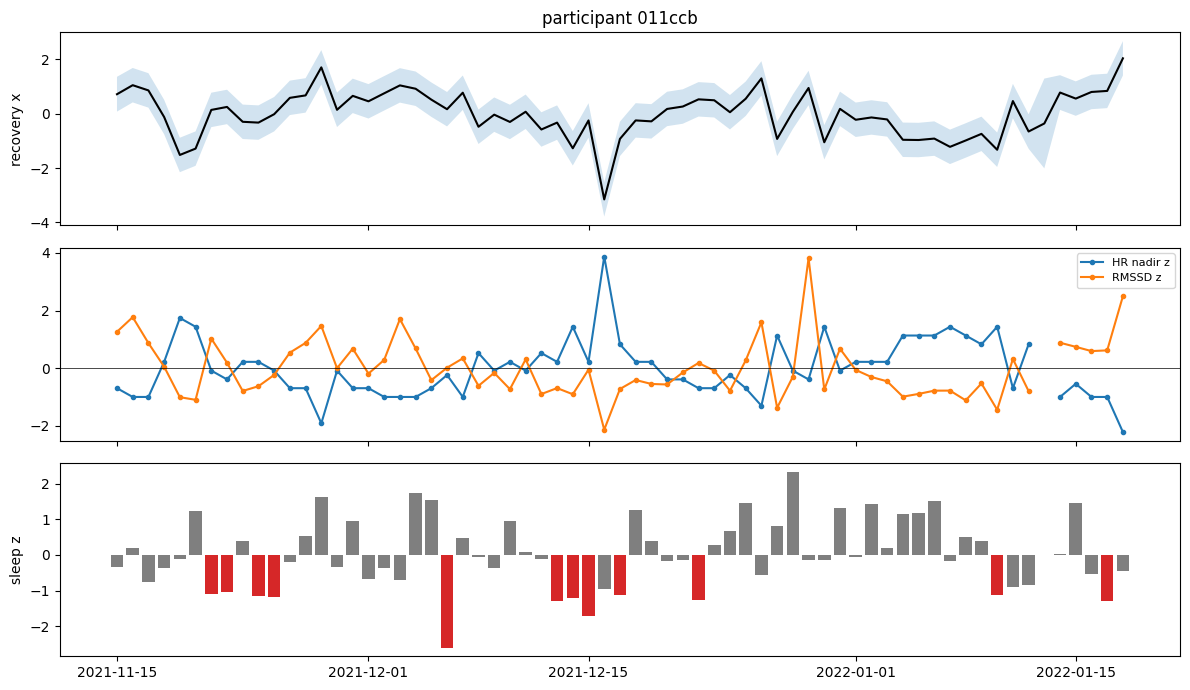

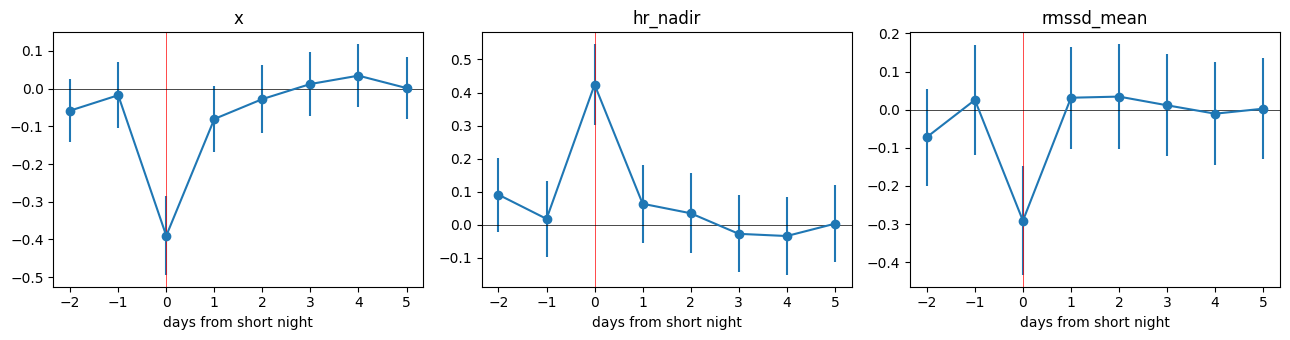

In [12]:
_, M1, V1 = run1(fit1.x)
pan["x"] = np.concatenate([M1[i, :Lens[i]] for i in range(N)])
pan["x_sd"] = np.sqrt(np.concatenate([V1[i, :Lens[i]] for i in range(N)]))
pid = pan.groupby("id").hr_nadir.count().idxmax(); g = pan[pan.id == pid]
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
ax[0].plot(g.date, g.x, c="k"); ax[0].fill_between(g.date, g.x - 2 * g.x_sd, g.x + 2 * g.x_sd, alpha=.2)
ax[0].set_ylabel("recovery x"); ax[0].set_title(f"participant {pid[-6:]}")
ax[1].plot(g.date, g.hr_nadir, "o-", ms=3, label="HR nadir z"); ax[1].plot(g.date, g.rmssd_mean, "o-", ms=3, label="RMSSD z")
ax[1].legend(fontsize=8); ax[1].axhline(0, c="k", lw=.5)
ax[2].bar(g.date, g.minutesAsleep, color=np.where(g.minutesAsleep < -1, "tab:red", "tab:gray")); ax[2].set_ylabel("sleep z")
plt.tight_layout(); plt.savefig(FIG / "recovery_one_person.png", dpi=150); plt.show()

ev_rows = []
for _, g in pan.groupby("id"):
    g = g.reset_index(drop=True)
    for t0_ in g.index[g.minutesAsleep < -1]:
        for k in range(-2, 6):
            if 0 <= t0_ + k < len(g):
                ev_rows.append({"k": k, "x": g.x[t0_ + k], "hr_nadir": g.hr_nadir[t0_ + k], "rmssd_mean": g.rmssd_mean[t0_ + k]})
ev = pd.DataFrame(ev_rows).groupby("k").agg(["mean", "sem"])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for a, col in zip(ax, ["x", "hr_nadir", "rmssd_mean"]):
    a.errorbar(ev.index, ev[col]["mean"], 1.96 * ev[col]["sem"], marker="o"); a.axvline(0, c="r", lw=.5); a.axhline(0, c="k", lw=.5)
    a.set_title(col); a.set_xlabel("days from short night")
plt.tight_layout(); plt.savefig(FIG / "event_locked.png", dpi=150); plt.show()

Does adding the recovery state to the mood classifier help? **Result:** 0.353 against 0.352 without it.

In [13]:
dlr2 = dlr.merge(pan[["id", "date", "x"]], on=["id", "date"], how="left")
tr2, te2 = dlr2[dlr2["rank"] <= 1 - TEST_FRAC], dlr2[dlr2["rank"] > 1 - TEST_FRAC]
res_x = pd.DataFrame([(name, *fit_eval(tr2, te2, cols)) for name, cols in
                      [("time + previous mood", []), ("+ recovery state", ["x"]), ("+ state + night features", ["x"] + F)]],
                     columns=["model", "bal_acc", "macro_f1"]).round(3)
res_x

,model,bal_acc,macro_f1
0,time + previous mood,0.352,0.304
1,+ recovery state,0.353,0.306
2,+ state + night features,0.343,0.305


## 8. State space with mood inside and several hidden states
Mood enters the model as daily valence and arousal (z scored on training days only). Mood on test days is hidden during fitting and predicted
one step ahead. The loading matrix is lower triangular to fix rotation; 1, 2 and 3 states are compared by BIC.

In [14]:
MOODC = ["valence", "arousal"]; ALL = OBS + MOODC; KA = len(ALL)
rv = reps.copy(); rv[MOODC] = pd.DataFrame(rv.MOOD.map(VA).tolist(), index=rv.index)
dm = rv.groupby(["id", "date"])[MOODC].mean().reset_index()
pan2 = pan.merge(dm, on=["id", "date"], how="left").sort_values(["id", "date"]).reset_index(drop=True)
pan2["rank"] = pan2.groupby("id").date.rank(pct=True); is_tr = pan2["rank"] <= 1 - TEST_FRAC
for c in MOODC:
    mu_ = pan2[is_tr].groupby("id")[c].mean(); sd_ = pan2[is_tr].groupby("id")[c].std()
    pan2[c] = ((pan2[c] - pan2.id.map(mu_)) / pan2.id.map(sd_)).clip(-Z_CLIP, Z_CLIP)
Yfull = np.full((N, T, KA), np.nan); TEST = np.zeros((N, T), bool)
for i, (pid, g) in enumerate(pan2.groupby("id", sort=False)):
    assert pid == ids[i]
    Yfull[i, :len(g)] = g[ALL].to_numpy(); TEST[i, :len(g)] = (g["rank"] > 1 - TEST_FRAC).to_numpy()
Yfit = Yfull.copy(); Yfit[..., -2:][TEST] = np.nan
print("days with mood:", int(np.isfinite(Yfull[..., -1]).sum()), " hidden for test:", int((np.isfinite(Yfull[..., -1]) & TEST).sum()))

days with mood: 2168  hidden for test: 552


In [15]:
def unpackS(th, S):
    i = 0; phi = np.tanh(th[i:i + S]); i += S
    B = th[i:i + 2 * S].reshape(S, 2); i += 2 * S
    C = np.zeros((KA, S))
    for s in range(S): C[s:, s] = th[i:i + KA - s]; i += KA - s
    return phi, B, C, 0.05 + np.exp(th[i:i + KA])

def runS(th, S, Yuse):
    phi, B, C, rn = unpackS(th, S); I = np.eye(S)
    m = np.zeros((N, S)); Pm = np.tile(I, (N, 1, 1)); ll = 0.0
    Mp = np.zeros((N, T, S)); Mf = np.zeros((N, T, S))
    for t in range(T):
        m = m * phi + U[:, t] @ B.T; Pm = phi[:, None] * Pm * phi[None, :] + I
        Mp[:, t] = m
        y = Yuse[:, t]; o = ~np.isnan(y); e = np.where(o, y - m @ C.T, 0.0); Dw = o / rn
        CtDC = np.einsum("ks,nk,kj->nsj", C, Dw, C); CtDe = np.einsum("ks,nk->ns", C, Dw * e)
        Pn = np.linalg.inv(np.linalg.inv(Pm) + CtDC)
        quad = (Dw * e * e).sum(1) - np.einsum("ns,nsj,nj->n", CtDe, Pn, CtDe)
        logdet = (o * np.log(rn)).sum(1) + np.linalg.slogdet(I + Pm @ CtDC)[1]
        ll += (-0.5 * (quad + logdet + o.sum(1) * np.log(2 * np.pi))).sum()
        m = m + np.einsum("nsj,nj->ns", Pn, CtDe); Pm = Pn; Mf[:, t] = m
    return ll, Mp, Mf

fitsS = {}; nobsS = int(np.isfinite(Yfit).sum())
for S in [1, 2, 3]:
    rng = np.random.default_rng(0)
    th0 = np.r_[np.full(S, .5), np.zeros(2 * S), rng.normal(0, .3, sum(KA - s for s in range(S))), np.full(KA, np.log(.7))]
    t0 = time(); f = minimize(lambda th: -runS(th, S, Yfit)[0], th0, method="L-BFGS-B", options={"maxiter": 400})
    fitsS[S] = f
    print(f"S={S}  loglik={-f.fun:.1f}  params={len(th0)}  BIC={2 * f.fun + len(th0) * np.log(nobsS):.1f}  {time()-t0:.0f}s  {f.message}")

S=1  loglik=-30659.5  params=25  BIC=61569.6  10s  CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
S=2  loglik=-30485.6  params=38  BIC=61352.0  37s  CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
S=3  loglik=-30349.1  params=50  BIC=61199.3  85s  CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH


**Result:** BIC selects 3 states. State 1 is autonomic strain (HR nadir +0.87, RMSSD −0.63, half life 0.6 days); state 2 is the within night
trajectory (nadir timing, late minus early RMSSD, no persistence); state 3 is fragmentation (wake rate, deep fraction). Valence and arousal load
at most 0.04 on any state.

In [16]:
S_best = min(fitsS, key=lambda s: 2 * fitsS[s].fun + len(fitsS[s].x) * np.log(nobsS))   # override to inspect another S
phiS, BS, CS, rnS = unpackS(fitsS[S_best].x, S_best)
cols_ = [f"state{s + 1}" for s in range(S_best)]
print(f"chosen S={S_best}")
print(pd.DataFrame({"phi": phiS, "half_life_days": np.log(.5) / np.log(np.abs(phiS)), "b_sleep": BS[:, 0],
                    "b_steps_prev": BS[:, 1]}, index=cols_).round(3))
loadS = pd.DataFrame(CS, index=ALL, columns=cols_).round(2); loadS["noise"] = rnS.round(2)
loadS

chosen S=3
          phi  half_life_days  b_sleep  b_steps_prev
state1  0.340           0.643   -0.193         0.154
state2  0.046           0.226   -0.139        -0.058
state3  0.048           0.228   -0.037        -0.002


,state1,state2,state3,noise
hr_nadir,0.87,0.00,0.00,0.06
rmssd_mean,-0.63,0.10,0.00,0.49
hr_drop,0.01,-0.28,0.03,0.86
deep_frac,0.06,0.01,0.35,0.82
wake_per_h,-0.01,0.08,0.89,0.12
temp_mean,0.14,0.06,0.07,0.90
nadir_frac,0.12,-0.54,0.07,0.65
rmssd_late_minus_early,0.03,-0.58,0.15,0.58
deep_first_half,0.08,-0.10,-0.04,0.95
valence,0.01,-0.04,0.01,0.96


Held out valence and arousal: the model's one step prediction against the person mean and carry forward. **Result:** the model equals the person mean.

In [17]:
_, MpS, _ = runS(fitsS[S_best].x, S_best, Yfit)
predS = MpS @ CS.T
rows = []
for j, name in [(KA - 2, "valence"), (KA - 1, "arousal")]:
    y = Yfull[..., j]; prev = np.full_like(y, np.nan)
    for i in range(N):
        last = np.nan
        for t in range(T):
            prev[i, t] = last
            if np.isfinite(y[i, t]): last = y[i, t]
    k = TEST & np.isfinite(y) & np.isfinite(prev)
    rmse = lambda a: float(np.sqrt(np.mean((a[k] - y[k]) ** 2)))
    rows.append({"target": name, "n_days": int(k.sum()), "RMSE_model": rmse(predS[..., j]),
                 "RMSE_person_mean": rmse(np.zeros_like(y)), "RMSE_carry_forward": rmse(prev),
                 "corr_model": float(np.corrcoef(predS[..., j][k], y[k])[0, 1])})
pd.DataFrame(rows).round(3)

,target,n_days,RMSE_model,RMSE_person_mean,RMSE_carry_forward,corr_model
0,valence,552,1.027,1.027,1.310,0.093
1,arousal,552,1.046,1.045,1.341,-0.026


## 9. Hidden Markov model
Each day sits in one of K regimes with Gaussian physiology and a categorical distribution over the 7 moods; fitted with Baum Welch EM in log space
for K = 1 to 5. Mood on test days is hidden. Log loss on held out reports is compared with population and person mood frequencies.
**Result:** K = 5 by BIC, including one regime that isolates corrupt sleep records; the HMM matches the population baseline (1.79) while each
person's own frequencies reach 1.559.

In [18]:
GF = OBS + INP; FH = len(GF); CATS = VALID
cnt = (rv.groupby(["id", "date", "MOOD"]).size().unstack(fill_value=0)
         .reindex(columns=CATS, fill_value=0).reset_index())
hh = pan2.merge(cnt, on=["id", "date"], how="left"); hh[CATS] = hh[CATS].fillna(0)
seqs = []
for pid, g in hh.groupby("id", sort=False):
    Cg = g[CATS].to_numpy(); te = (g["rank"] > 1 - TEST_FRAC).to_numpy(); Cf = Cg.copy(); Cf[te] = 0
    seqs.append((pid, g[GF].to_numpy(dtype=float), Cg, Cf, te))
print(len(seqs), "people,", int(sum(s[3].sum() for s in seqs)), "training reports,",
      int(sum(s[2][s[4]].sum() for s in seqs)), "test reports")

def logB(Y, Cm, mu, var, lth):
    o = ~np.isnan(Y); y = np.where(o, Y, 0)
    g = -0.5 * (((y[:, None] - mu[None]) ** 2 / var[None] + np.log(2 * np.pi * var[None])) * o[:, None]).sum(2)
    return g + Cm @ lth.T

def fb(lb, lA, lpi):
    Tn, Kn = lb.shape; la = np.zeros((Tn, Kn)); lbk = np.zeros((Tn, Kn)); la[0] = lpi + lb[0]
    for t in range(1, Tn): la[t] = lb[t] + logsumexp(la[t - 1][:, None] + lA, 0)
    for t in range(Tn - 2, -1, -1): lbk[t] = logsumexp(lA + lb[t + 1][None] + lbk[t + 1][None], 1)
    ll = logsumexp(la[-1]); gam = np.exp(la + lbk - ll)
    xi = np.zeros((Kn, Kn))
    for t in range(Tn - 1): xi += np.exp(la[t][:, None] + lA + lb[t + 1][None] + lbk[t + 1][None] - ll)
    return ll, gam, xi, la

def fit_hmm(Kh, iters=150, seed=0):
    rng = np.random.default_rng(seed)
    mu = rng.normal(0, .5, (Kh, FH)); var = np.ones((Kh, FH)); th = np.full((Kh, 7), 1 / 7)
    A = np.full((Kh, Kh), .2 / max(Kh - 1, 1)); np.fill_diagonal(A, .8 if Kh > 1 else 1.); pi = np.full(Kh, 1 / Kh); prev_ll = -np.inf
    for it in range(iters):
        S0, Sxi = np.zeros(Kh), np.zeros((Kh, Kh)); Sw, Sy, Syy = (np.zeros((Kh, FH)) for _ in range(3)); Sc = np.zeros((Kh, 7)); LL = 0.0
        for _, Y, _, Cf, _ in seqs:
            ll, gam, xi, _ = fb(logB(Y, Cf, mu, var, np.log(th)), np.log(A), np.log(pi))
            o = ~np.isnan(Y); y = np.where(o, Y, 0)
            LL += ll; S0 += gam[0]; Sxi += xi; Sw += gam.T @ o; Sy += gam.T @ y; Syy += gam.T @ (y * y); Sc += gam.T @ Cf
        pi = S0 / S0.sum(); A = (Sxi + 1e-6) / (Sxi + 1e-6).sum(1, keepdims=True)
        mu = Sy / np.maximum(Sw, 1e-9); var = np.maximum(Syy / np.maximum(Sw, 1e-9) - mu ** 2, .05)
        th = (Sc + 1) / (Sc + 1).sum(1, keepdims=True)
        if LL - prev_ll < 1e-3: break
        prev_ll = LL
    return dict(mu=mu, var=var, th=th, A=A, pi=pi, ll=LL, K=Kh, iters=it + 1)

nobsH = sum(np.isfinite(s[1]).sum() + s[3].sum() for s in seqs); hmms = {}
for Kh in range(1, 6):
    t0 = time(); mh = fit_hmm(Kh); npar = (Kh - 1) + Kh * (Kh - 1) + 2 * Kh * FH + 6 * Kh
    mh["bic"] = -2 * mh["ll"] + npar * np.log(nobsH); hmms[Kh] = mh
    print(f"K={Kh}  loglik={mh['ll']:.1f}  BIC={mh['bic']:.1f}  iterations={mh['iters']}  {time()-t0:.0f}s")

57 people, 3633 training reports, 1196 test reports
K=1  loglik=-40843.9  BIC=81974.6  iterations=3  1s
K=2  loglik=-40255.1  BIC=81114.6  iterations=92  27s
K=3  loglik=-39473.2  BIC=79889.1  iterations=150  44s
K=4  loglik=-39237.9  BIC=79777.1  iterations=73  21s
K=5  loglik=-39028.3  BIC=79736.9  iterations=150  44s


In [21]:
K_best = min(hmms, key=lambda k: hmms[k]["bic"])        # override to inspect another K
mh = hmms[K_best]; sn = [f"S{k + 1}" for k in range(K_best)]
print(f"chosen K={K_best}")
print("mean dwell time (days):", dict(zip(sn, (1 / (1 - np.diag(mh['A']) + 1e-12)).round(1))))
print("\nphysiology means (per person z):"); print(pd.DataFrame(mh["mu"], columns=GF, index=sn).round(2).T)
print("\nmood probabilities per state:"); print(pd.DataFrame(mh["th"], columns=CATS, index=sn).round(2).T)

chosen K=5
mean dwell time (days): {'S1': np.float64(2.9), 'S2': np.float64(1.5), 'S3': np.float64(2.3), 'S4': np.float64(2.5), 'S5': np.float64(1.0)}

physiology means (per person z):
                          S1    S2    S3    S4    S5
hr_nadir                0.54  0.88 -0.83 -0.11  0.02
rmssd_mean             -0.58 -0.71  0.85  0.01 -0.01
hr_drop                -0.09  0.25 -0.12  0.09 -0.04
deep_frac              -0.02  0.03 -0.25 -0.04  2.75
wake_per_h              0.01 -0.54 -0.12  0.03  3.13
temp_mean               0.29 -0.23 -0.16  0.04 -0.01
nadir_frac              0.15  0.06 -0.29  0.16 -0.09
rmssd_late_minus_early -0.01  0.12 -0.15  0.09  0.22
deep_first_half        -0.00  0.38 -0.16  0.00 -0.06
minutesAsleep          -0.11 -0.11  0.09  0.09 -0.18
steps_prev             -0.05  0.38 -0.30  0.17 -0.01

mood probabilities per state:
                  S1    S2    S3    S4    S5
RESTED/RELAXED  0.10  0.23  0.17  0.40  0.27
TIRED           0.24  0.29  0.24  0.17  0.16
NEUTRAL      

In [22]:
tot = sum(s[3].sum(0) for s in seqs); pop = (tot + 1) / (tot + 1).sum()
def eval_hmm(m):
    out = {k: [0.0, 0.0] for k in ["hmm", "person", "population"]}
    for _, Y, Cg, Cf, te in seqs:
        _, _, _, la = fb(logB(Y, Cf, m["mu"], m["var"], np.log(m["th"])), np.log(m["A"]), np.log(m["pi"]))
        pm = np.exp(la - logsumexp(la, 1, keepdims=True)) @ m["th"]
        per = (Cf.sum(0) + 1) / (Cf.sum(0) + 1).sum()
        for t in np.where(te & (Cg.sum(1) > 0))[0]:
            for k, p in [("hmm", pm[t]), ("person", per), ("population", pop)]:
                out[k][0] -= (Cg[t] * np.log(p)).sum(); out[k][1] += Cg[t].sum()
    return {k: round(v[0] / v[1], 4) for k, v in out.items()}
pd.DataFrame({k: eval_hmm(hmms[k]) for k in hmms}).T.rename_axis("K")

,hmm,person,population
K,,,
1,1.7940,1.5591,1.794
2,1.7951,1.5591,1.794
3,1.7962,1.5591,1.794
4,1.7925,1.5591,1.794
5,1.7958,1.5591,1.794


## 10. Per person coupling
Mixed model: valence (or arousal) on the recovery state with a random slope per person, controlling for the previous day's mood.
Person slopes are shrunk toward the mean, so treat them as descriptive.
**Result:** average valence slope 0.006 (95% CI −0.06 to 0.07); slope variance 0.009 (SE 0.010); no person above 0.2; yesterday's mood is the only
reliable predictor.


=== valence: 1918 days, 53 people
               Coef. Std.Err.      z  P>|z|  [0.025 0.975]
Intercept      0.002    0.049  0.032  0.975  -0.095  0.098
x              0.006    0.034  0.164  0.870  -0.062  0.073
valence_prev   0.133    0.023  5.843  0.000   0.088  0.178
Group Var      0.086                                      
Group x x Cov  0.001    0.028                             
x Var          0.009    0.010                             
person slopes: mean 0.006, sd 0.038, range -0.08 to 0.13, |slope|>0.2: 0

=== arousal: 1918 days, 53 people
                Coef. Std.Err.       z  P>|z|  [0.025 0.975]
Intercept      -0.016    0.051  -0.317  0.751  -0.115  0.083
x               0.044    0.035   1.256  0.209  -0.025  0.113
arousal_prev    0.090    0.023   3.922  0.000   0.045  0.135
Group Var       0.091                                       
Group x x Cov  -0.003    0.027                              
x Var           0.012    0.010                              
person slopes: me

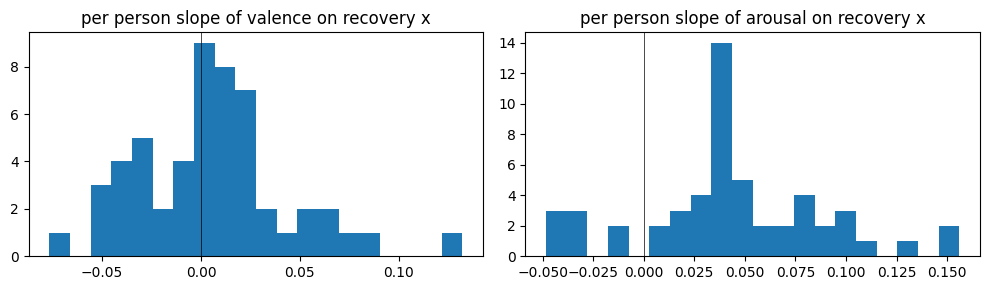

In [23]:
mdl = pan2[["id", "date", "x"] + MOODC].copy()
for c in MOODC: mdl[c + "_prev"] = mdl.groupby("id")[c].shift(1)
res_ml = {}
for c in MOODC:
    dd = mdl.dropna(subset=[c, "x", c + "_prev"])
    f = smf.mixedlm(f"{c} ~ x + {c}_prev", dd, groups=dd["id"], re_formula="~x").fit(method="lbfgs")
    sl = pd.Series({k: f.fe_params["x"] + v.iloc[-1] for k, v in f.random_effects.items()})
    res_ml[c] = (f, sl)
    print(f"\n=== {c}: {len(dd)} days, {dd.id.nunique()} people")
    print(f.summary().tables[1])
    print(f"person slopes: mean {sl.mean():.3f}, sd {sl.std():.3f}, range {sl.min():.2f} to {sl.max():.2f}, |slope|>0.2: {(sl.abs() > .2).sum()}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for a, c in zip(ax, MOODC):
    a.hist(res_ml[c][1], bins=20); a.axvline(0, c="k", lw=.5); a.set_title(f"per person slope of {c} on recovery x")
plt.tight_layout(); plt.savefig(FIG / "person_slopes.png", dpi=150); plt.show()

## 11. Export for the Streamlit recovery tracker
Writes `d2_export.zip` (daily states, mood reports, fitted parameters, figures). Unzip it into `data/processed/d2/` of the repository.

In [24]:
import json, zipfile
EXP = BASE / "d2_export"; EXP.mkdir(exist_ok=True)
_, _, MfS = runS(fitsS[S_best].x, S_best, Yfit)
daily_out = pan2[["id", "date", "x", "x_sd", "minutesAsleep", "steps_prev"] + OBS + MOODC].copy()
for s in range(S_best): daily_out[f"state{s+1}"] = np.concatenate([MfS[i, :Lens[i], s] for i in range(N)])
reg = []
for (pid, Y, Cg, Cf, te) in seqs:
    _, gam, _, _ = fb(logB(Y, Cf, mh["mu"], mh["var"], np.log(mh["th"])), np.log(mh["A"]), np.log(mh["pi"]))
    reg.append(gam.argmax(1) + 1)
daily_out["hmm_state"] = np.concatenate(reg)
daily_out.to_parquet(EXP / "daily_states.parquet")
reps[["id", "t", "date", "slot", "MOOD"]].to_parquet(EXP / "mood_reports.parquet")
json.dump({"phi1": float(phi1), "b1": b1.tolist(), "q1": float(q1), "c1": c1.tolist(), "obs": OBS,
           "phiS": phiS.tolist(), "BS": BS.tolist(), "CS": CS.tolist(), "all": ALL,
           "hmm_mu": mh["mu"].tolist(), "hmm_theta": mh["th"].tolist(), "hmm_A": mh["A"].tolist(), "gf": GF, "cats": CATS,
           "res_lr": res_lr.to_dict("records"), "res_x": res_x.to_dict("records"),
           "funnel": funnel.to_dict("records")}, open(EXP / "params.json", "w"))
with zipfile.ZipFile(BASE / "d2_export.zip", "w") as z:
    for p in list(EXP.iterdir()) + list(FIG.glob("*.png")): z.write(p, p.name)
print("written", BASE / "d2_export.zip", round((BASE / "d2_export.zip").stat().st_size / 1e6, 1), "MB")


written /home/m.phatak/Data Analysis Zenodo/d2_export.zip 0.8 MB
